# Simple Linear Regression
### First Machine Learning Algorithm · Supervised Learning · Regression

**Core idea:** Learn a best-fit line from training data and use it to predict a continuous output for a new input.

This notebook demonstrates the introductory ideas with the lecture's example of predicting **Height from Weight**. It is an illustrative, tiny dataset—not enough data for a reliable real-world height prediction.


## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression


## 2. Create the training data

In [2]:
# Input feature: Weight in kilograms
# Output target: Height in centimetres
X = np.array([[74], [80], [75]])
y = np.array([170, 180, 175.5])

df = pd.DataFrame({"Weight (kg)": X.ravel(), "Height (cm)": y})
df


,Weight (kg),Height (cm)
0,74,170.0
1,80,180.0
2,75,175.5


## 3. Plot the observed data points

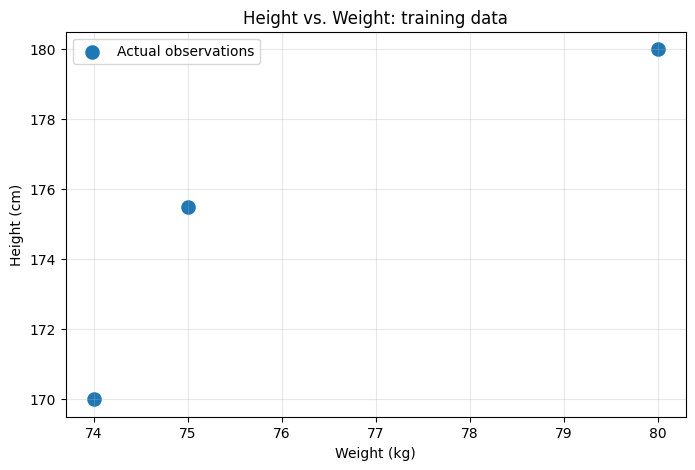

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(X.ravel(), y, s=90, label="Actual observations")
plt.xlabel("Weight (kg)")
plt.ylabel("Height (cm)")
plt.title("Height vs. Weight: training data")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## 4. Train a Simple Linear Regression model

In [4]:
model = LinearRegression()
model.fit(X, y)

print("Learned slope:", model.coef_[0])
print("Learned intercept:", model.intercept_)
print(f"Learned line: Height = {model.coef_[0]:.3f} × Weight + {model.intercept_:.3f}")


Learned slope: 1.419354838709678
Learned intercept: 66.82258064516125
Learned line: Height = 1.419 × Weight + 66.823


## 5. Visualize the best-fit line

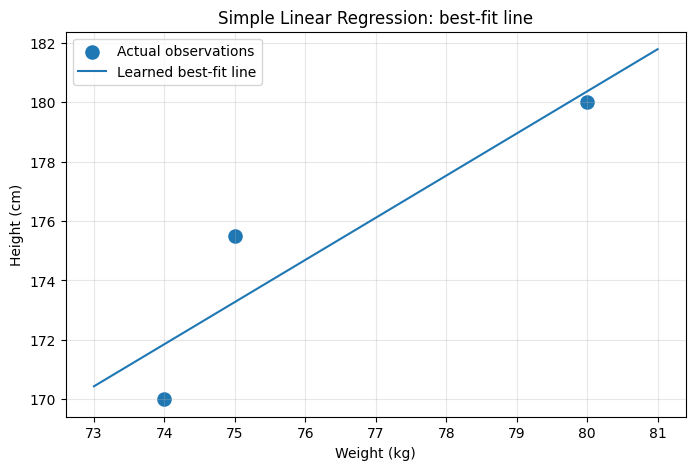

In [5]:
x_line = np.linspace(X.min() - 1, X.max() + 1, 200).reshape(-1, 1)
y_line = model.predict(x_line)

plt.figure(figsize=(8, 5))
plt.scatter(X.ravel(), y, s=90, label="Actual observations")
plt.plot(x_line.ravel(), y_line, label="Learned best-fit line")
plt.xlabel("Weight (kg)")
plt.ylabel("Height (cm)")
plt.title("Simple Linear Regression: best-fit line")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## 6. Predict for a new input

In [6]:
new_weight = np.array([[77]])
predicted_height = model.predict(new_weight)[0]

print(f"New weight: {new_weight[0, 0]} kg")
print(f"Predicted height: {predicted_height:.2f} cm")


New weight: 77 kg
Predicted height: 176.11 cm


## 7. Actual values vs. predicted values

A residual is the signed difference between the actual value and the predicted value:

\\[
e_i = y_i - \\hat{y}_i
\\]

The vertical gap between a data point and the line represents the magnitude of its residual on this graph.

In [7]:
predicted_train = model.predict(X)
residuals = y - predicted_train

results = pd.DataFrame({
    "Weight (kg)": X.ravel(),
    "Actual Height (cm)": y,
    "Predicted Height (cm)": predicted_train,
    "Residual (actual - predicted)": residuals
})
results


,Weight (kg),Actual Height (cm),Predicted Height (cm),Residual (actual - predicted)
0,74,170.0,171.854839,-1.854839
1,80,180.0,180.370968,-0.370968
2,75,175.5,173.274194,2.225806


### Visualize residuals

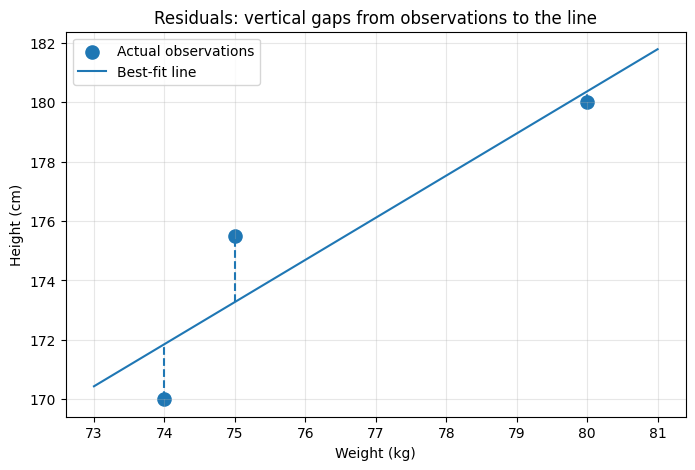

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(X.ravel(), y, s=90, label="Actual observations")
plt.plot(x_line.ravel(), y_line, label="Best-fit line")

for x_value, actual, predicted in zip(X.ravel(), y, predicted_train):
    plt.vlines(x_value, min(actual, predicted), max(actual, predicted), linestyles="dashed")

plt.xlabel("Weight (kg)")
plt.ylabel("Height (cm)")
plt.title("Residuals: vertical gaps from observations to the line")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## 8. What does “best fit” mean?

Ordinary Linear Regression in scikit-learn fits the line by minimizing the **sum of squared residuals**. The introductory lecture describes this more generally as minimizing overall error; the squared-error objective is the precise least-squares version.

This tiny dataset is for understanding the mechanics, not for making reliable real-world height predictions.

In [9]:
squared_errors = residuals ** 2
print("Residuals:", residuals)
print("Sum of squared errors:", squared_errors.sum())
print("Mean squared error:", np.mean(squared_errors))


Residuals: [-1.85483871 -0.37096774  2.22580645]
Sum of squared errors: 8.53225806451617
Mean squared error: 2.8440860215053902


## 9. Self-check

1. Why is this a supervised learning problem?
2. Why is this Simple Linear Regression rather than Multiple Linear Regression?
3. Which variable is the input, and which is the output?
4. What does the best-fit line represent?
5. What is a residual?
6. Why should you be cautious about using this tiny dataset for real predictions?

### Answers

1. The training data includes known output values (heights).
2. There is one input feature: weight.
3. Weight is the input; height is the output.
4. It represents the relationship learned from the training examples.
5. The signed difference between an actual value and its predicted value.
6. Three observations are far too few to establish a reliable real-world relationship; the example is for learning the algorithm's mechanics.
